In [64]:
# Messung nach reaktor
# Messtag 05.05.2026

# configuration
# 250 nml-min Reaktor
# 250 nml-min Matrix
# 2 bar abs
# 250 °C


In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import ICIW_Plots

plt.style.use("ICIWstyle")
plt.rcParams["font.size"] = 7

In [66]:
n_dot_old = np.load(r"C:\Users\admin\iCloudDrive\03 - Universität Master\Research Internship\Python\AZA_001\nRTD-AZA_FBA_THA\Experiments\HSA_004\data\FBA-E-19032025_250ml-min_2bar_250_TotalSystem_composition.npy")
timestamps = np.load(r"C:\Users\admin\iCloudDrive\03 - Universität Master\Research Internship\Python\AZA_001\nRTD-AZA_FBA_THA\Experiments\HSA_004\data\FBA-E-19032025_250ml-min_2bar_250_TotalSystem_times.npy")

n_dot = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V3_reactor_varVdot_varTemp\results\data_ptk_nocat_reactor_150°C_1bar_reactor125mlmin_matrix250mlmin.npz")['n_dot'].T[:,[0, 1, 2]]
t_source = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V3_reactor_varVdot_varTemp\results\data_ptk_nocat_reactor_150°C_1bar_reactor125mlmin_matrix250mlmin.npz")['time_delta']

In [67]:
print("n_dot_old shape",n_dot_old.shape)
print("n_dot shape",n_dot.shape)

print("timestamps shape",timestamps.shape)
print("t_source shape",t_source.shape)

n_dot_old shape (149166, 3)
n_dot shape (203732, 3)
timestamps shape (149166,)
t_source shape (203732,)


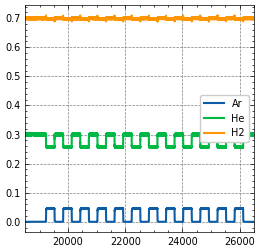

In [68]:
plt.plot(timestamps, n_dot_old[:,0], label="Ar", color="C0")
plt.plot(timestamps, n_dot_old[:,1], label="He", color="C1")
plt.plot(timestamps, n_dot_old[:,2], label="H2", color="C2")
plt.xlim(18500,26500)
plt.legend()

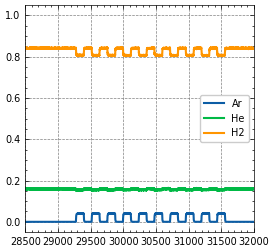

In [69]:
plt.plot(t_source, n_dot[:,0], label="Ar", color="C0")
plt.plot(t_source, n_dot[:,1], label="He", color="C1")
plt.plot(t_source, n_dot[:,2], label="H2", color="C2")
#plt.xlim(14*60+32.6, 15*60)
plt.xlim(28500,32000)
# plt.scatter(15*60, 0.2)
# plt.xlim(14*60, 16*60)
#plt.xlim(14.5*60,)
plt.legend()

In [70]:
time_delta = t_source - t_source[0]

np.savez(
    "nRTD_ptk_nachreaktor_nocat_150°C_aequi_1bar_reactor125mlmin_matrix250mlmin.npz",
    n_dot=n_dot.T,
    time_delta=time_delta,
)

t_range = (time_delta.min(), time_delta.max())

In [71]:
# create array with half-period times

t_out = (0.0, 120.0)
n_out = int(4 * (t_out[1] - t_out[0]) + 1)
delta_t_out = (t_out[1] - t_out[0]) / (n_out - 1)
t_offset = 34075 # offset until experiment starts
t_halfperiod = 120 # 2min half-period duration
t_kernel = (0, 80)
n_kernel = int(((t_kernel[1] - t_kernel[0]) / delta_t_out) + 1)
t_in = (0, t_out[1] - t_kernel[1])
n_in = int(((t_in[1] - t_in[0]) / delta_t_out) + 1)

switching_times = np.full((10,), t_halfperiod) + np.array([0.05,
                                                          0.18,
                                                          0.27,
                                                          0.33,
                                                          0.26,
                                                          0.18,
                                                          0.28,
                                                          0.27,
                                                          0.27,
                                                          0.03])
print(switching_times)

# t_offset = t_source[-1] - sum(switching_times)
# print(t_offset)
switching_times = np.insert(switching_times, 0, t_offset)
switching_times = np.cumsum(switching_times)
print(switching_times)

intervals = [
    (switching_times[i], switching_times[i + 1])
    for i in range(len(switching_times) - 1)
]
print(intervals)

[120.05 120.18 120.27 120.33 120.26 120.18 120.28 120.27 120.27 120.03]
[34075.   34195.05 34315.23 34435.5  34555.83 34676.09 34796.27 34916.55
 35036.82 35157.09 35277.12]
[(np.float64(34075.0), np.float64(34195.05)), (np.float64(34195.05), np.float64(34315.23)), (np.float64(34315.23), np.float64(34435.5)), (np.float64(34435.5), np.float64(34555.83)), (np.float64(34555.83), np.float64(34676.090000000004)), (np.float64(34676.090000000004), np.float64(34796.270000000004)), (np.float64(34796.270000000004), np.float64(34916.55)), (np.float64(34916.55), np.float64(35036.82)), (np.float64(35036.82), np.float64(35157.09)), (np.float64(35157.09), np.float64(35277.119999999995))]


In [72]:
print(time_delta.shape)
print(n_dot.shape)

(203732,)
(203732, 3)


In [73]:
interp = scipy.interpolate.interp1d(
    time_delta,
    n_dot.T,
    kind="linear",
    fill_value="extrapolate",
)

In [74]:
t = np.linspace(*t_range, 4810)
n_dot_interp = interp(t)

<>:5: SyntaxWarning: invalid escape sequence '\;'
<>:6: SyntaxWarning: invalid escape sequence '\;'
<>:5: SyntaxWarning: invalid escape sequence '\;'
<>:6: SyntaxWarning: invalid escape sequence '\;'
C:\Users\admin\AppData\Local\Temp\ipykernel_7120\1302250210.py:5: SyntaxWarning: invalid escape sequence '\;'
  xlabel="$t\;/\;\mathrm{s}$",
C:\Users\admin\AppData\Local\Temp\ipykernel_7120\1302250210.py:6: SyntaxWarning: invalid escape sequence '\;'
  ylabel="$x\;/\; 1$",


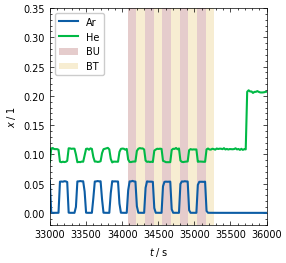

In [75]:
fig = plt.figure()
ax = ICIW_Plots.make_square_ax(
    fig=fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$t\;/\;\mathrm{s}$",
    ylabel="$x\;/\; 1$",
    xlim=(33000, 36000),
    ylim=(-0.02, 0.35),
)
ax.grid(False)
plt.plot(t, n_dot_interp[0], label="Ar")
plt.plot(t, n_dot_interp[1], label="He")


for interval in intervals[::2]:
    plt.fill_betweenx(
        [-0.1, 0.4],
        interval[0],
        interval[1],
        alpha=0.2,
        color="maroon",
        edgecolor=None,
        zorder=-1,
        label="BU",
    )
for interval in intervals[1::2]:
    plt.fill_betweenx(
        [-0.1, 0.4],
        interval[0],
        interval[1],
        alpha=0.2,
        color="goldenrod",
        edgecolor=None,
        zorder=-1,
        label="BT",
    )
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.savefig("exp_data_with_halfperiods.png", dpi=600)

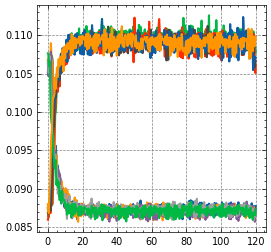

In [76]:
fig = plt.figure()
for interval in intervals:

    t = np.linspace(interval[0], interval[0] + 120, 480 + 1)

    n_dot_interp = interp(t)

    plt.plot(t - interval[0], n_dot_interp[1])

In [77]:
%pip install torch
%pip install lightning

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.Defaulting to user installation because normal site-packages is not writeable




[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [78]:
import sys

sys.path.append(r"C:\Users\admin\Documents\GitHub\THA\lib")
from pathlib import Path
from nRTD.rtd_fitting import RTDDataModule

data_total_system = RTDDataModule(
    batch_size=32, # 10 half-periods, 2 temperature, 4 different capillary positions
    data_file=Path(
        r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\C_nachreaktor_2barabs\nRTD_ptk_nachreaktor_nocat_150°C_aequi_1bar_reactor125mlmin_matrix250mlmin.npz"),
    switching_times=switching_times,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)

In [79]:
data_total_system.setup("fit")
data_total_system.x[0]

tensor([[8.5553e-05, 8.5553e-05, 8.5553e-05, 8.5553e-05, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02, 5.3008e-02,
         5.3008e-02, 5.3008e

In [80]:
print(data_total_system.x.shape) # 48 = 3 * 16, 3 components

torch.Size([20, 1, 161])


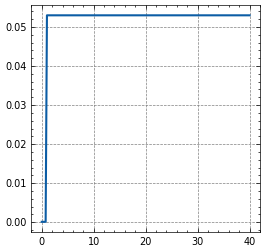

In [81]:
%matplotlib inline
plt.plot(data_total_system.t_in[0,:], data_total_system.x[0,0,:])
plt.show()
plt.close()

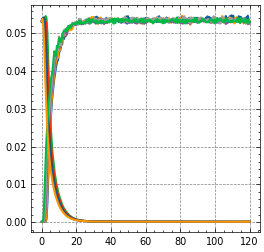

In [82]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="Ar")
plt.show()
plt.close()

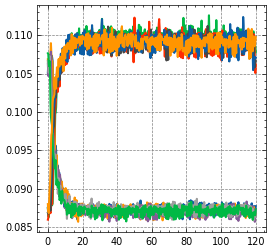

In [83]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="He")
plt.show()
plt.close()

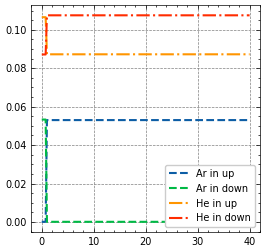

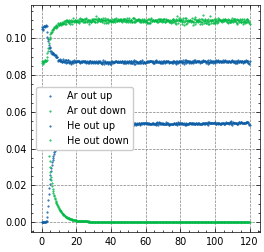

In [84]:
%matplotlib notebook
%matplotlib inline

fig = plt.figure()
index = 0
plt.plot(
    data_total_system.t_in[index],
    data_total_system.x[index].squeeze(),
    ls="--", label ='Ar in up'
)
plt.plot(
    data_total_system.t_in[index + 2],
    data_total_system.x[index + 2].squeeze(),
    ls="--", label = 'Ar in down'
)
plt.plot(
    data_total_system.t_in[index+1],
    data_total_system.x[index+1].squeeze(),
    ls="-.", label ='He in up'
)
plt.plot(
    data_total_system.t_in[index + 3],
    data_total_system.x[index + 3].squeeze(),
    ls="-.", label ='He in down'
)
plt.legend()
plt.show()


plt.plot(
    data_total_system.t_out[index],
    data_total_system.y[index].squeeze(),
    "o",
    c="C0",
    markersize=0.5, label ='Ar out up'
)
plt.plot(
    data_total_system.t_out[index + 2],
    data_total_system.y[index + 2].squeeze(),
    "o",
    c="C1",
    markersize=0.5, label ='Ar out down'
)
plt.plot(
    data_total_system.t_out[index+1],
    data_total_system.y[index+1].squeeze(),
    "o",
    c="C0",
    markersize=0.5, label ='He out up'
)
plt.plot(
    data_total_system.t_out[index + 3],
    data_total_system.y[index + 3].squeeze(),
    "o",
    c="C1",
    markersize=0.5, label ='He out down'
)
plt.legend()
plt.show()